In [19]:
import numpy as np
import pandas as pd
data = np.load("data/training_data/mixed_samples/1healthy.npy")

In [60]:
heart = pd.DataFrame(data[5], columns=["x", "y", "z", "type"])
pos_summaries = []
pos_summary = heart.mean()[:3].T.to_numpy().flatten()
pos_summaries.append(pos_summary)
pos_vector = np.concatenate(pos_summaries)
pos_vector

array([-10.27114276,  -4.51356876,  45.38515894])

In [63]:
# from pathlib import Path
# folder = Path("data/training_data/mixed_samples")
# files = sorted(folder.glob("*.npy"))
# n_files = len(files)
# sample = np.load(files[0])

# pos_vector_slices = []
# for i in range(len(files)):
#     heart = np.load(files[i])
#     pos_vector_slice = []
#     for time_frame in range(10):
#         heart_slice = pd.DataFrame(heart[time_frame], columns=["x", "y", "z", "type"])
#         pos_summaries = []
#         for type in [0, 1, 2]:
#             pos_summary = heart_slice[heart_slice["type"] == type].describe().iloc[1:, :3].T.to_numpy().flatten()
#             pos_summaries.append(pos_summary)
#         pos_vector = np.concatenate(pos_summaries)
#         pos_vector_slice.append(pos_vector)
#     pos_vector_slices.append(np.concatenate(pos_vector_slice))

from pathlib import Path
folder = Path("data/training_data/mixed_samples")
files = sorted(folder.glob("*.npy"))
n_files = len(files)
sample = np.load(files[0])

pos_vector_slices = []
for i in range(len(files)):
    heart = np.load(files[i])
    pos_vector_slice = []
    for time_frame in range(10):
        heart_slice = pd.DataFrame(heart[time_frame], columns=["x", "y", "z", "type"])
        pos_summaries = []
        for type in [0, 1, 2]:
            pos_summary = heart_slice[heart_slice["type"] == type].median()[:3].T.to_numpy().flatten()
            pos_summaries.append(pos_summary)
        pos_vector = np.concatenate(pos_summaries)
        pos_vector_slice.append(pos_vector)
    pos_vector_slices.append(np.concatenate(pos_vector_slice))

# from pathlib import Path
# folder = Path("data/training_data/mixed_samples")
# files = sorted(folder.glob("*.npy"))
# n_files = len(files)
# sample = np.load(files[0])

# pos_vector_slices = []
# for i in range(len(files)):
#     heart = np.load(files[i])
#     pos_vector_slice = []
#     for time_frame in range(10):
#         heart_slice = pd.DataFrame(heart[time_frame], columns=["x", "y", "z", "type"])
#         pos_summaries = []
#         pos_summary = heart_slice.describe().iloc[1:, :3].T.to_numpy().flatten()
#         pos_summaries.append(pos_summary)
#         pos_vector = np.concatenate(pos_summaries)
#         pos_vector_slice.append(pos_vector)
#     pos_vector_slices.append(np.concatenate(pos_vector_slice))

In [88]:
from sklearn.decomposition import PCA

components_across_frames = []
for frame in range(10):
    flattened_hearts = []
    for i in range(n_files):
        heart = np.load(files[i])
        heart_slice = pd.DataFrame(heart[frame], columns=["x", "y", "z", "type"])
        x = heart_slice["x"].to_numpy()
        y = heart_slice["y"].to_numpy()
        z = heart_slice["z"].to_numpy()
        flattened_hearts.append(np.concatenate((x, y, z)))

    flattened_hearts = pd.DataFrame(flattened_hearts).T.to_numpy()
    pca = PCA(n_components=10)
    pca.fit(flattened_hearts)

    components_across_frames.append(pd.DataFrame(pca.components_).T.to_numpy())
    

/opt/homebrew/Caskroom/miniconda/base/envs/fla/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/opt/homebrew/Caskroom/miniconda/base/envs/fla/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/opt/homebrew/Caskroom/miniconda/base/envs/fla/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/opt/homebrew/Caskroom/miniconda/base/envs/fla/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/opt/homebrew/Caskroom/miniconda/base/envs/fla/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/opt/homebrew/Caskroom/miniconda/base/envs/fla/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarni

In [95]:
components_list = []
for i in range(len(components_across_frames)):
    components_list.append(np.concatenate(components_across_frames[i]))

In [101]:
len(components_across_frames)

10

In [93]:
entry

array([[ 0.03722873,  0.04527811,  0.0023338 , ..., -0.01320808,
         0.01556917,  0.02814169],
       [ 0.03623112, -0.00366104,  0.00884678, ..., -0.00035762,
         0.04259669, -0.00340458],
       [ 0.03401203, -0.0074718 ,  0.0403734 , ..., -0.00824973,
        -0.02634615,  0.02510407],
       ...,
       [ 0.03468365, -0.04959384, -0.01126543, ..., -0.01307095,
        -0.00255826, -0.02469367],
       [ 0.03794124,  0.04572169,  0.04368015, ..., -0.06898085,
        -0.03440089, -0.01261938],
       [ 0.03533124, -0.02461386,  0.00806438, ...,  0.04060431,
         0.06537067,  0.03330185]], shape=(900, 10))

In [65]:
X_heart = pd.DataFrame(pos_vector_slices)
X_heart.columns = [f"f{i}" for i in range(len(X_heart.columns))]
X_heart

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,...,f80,f81,f82,f83,f84,f85,f86,f87,f88,f89
0,-0.514963,3.374812,49.632786,1.115070,0.801524,49.706747,-36.221745,13.968225,56.675125,-1.104652,...,53.537365,1.030741,3.220125,47.758835,2.214294,0.579159,47.936180,-33.923388,13.596904,53.620932
1,2.768244,-0.057116,47.900766,4.107380,-2.366482,47.900501,-30.764233,10.652346,55.674973,3.213305,...,51.146542,4.096400,-0.139915,47.178038,4.532485,-2.372985,46.749157,-30.272385,10.059376,53.435305
2,0.628554,-1.182741,46.790836,2.396172,-2.476284,46.913771,-27.664928,10.974639,54.080128,0.594361,...,50.216032,1.221921,-1.227988,45.797827,2.751119,-2.490931,45.609598,-26.747929,10.607239,51.619703
3,1.011964,0.108805,44.013063,1.848797,-2.305661,43.868488,-31.590164,8.142216,47.757938,0.532977,...,45.226789,1.682211,0.447310,43.811249,2.383386,-1.979587,43.555340,-30.508758,8.340780,46.781761
4,-0.702774,-1.245948,43.186646,1.336442,-3.344887,44.431944,-27.690139,10.648643,55.367529,-1.697815,...,50.524496,-0.332387,-1.114546,42.172970,1.652178,-3.007629,43.267832,-26.636893,10.641410,53.672489
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,-0.784492,2.478307,38.396839,0.418654,0.174148,38.518368,-29.070380,10.584924,42.709930,-1.087673,...,39.327362,0.065921,2.038291,36.678509,1.107691,-0.061314,36.723164,-27.124086,9.961537,39.959564
896,-0.848739,-9.291170,40.645832,0.716774,-9.206911,38.875919,-33.452368,0.120896,41.228573,0.210347,...,38.616480,-0.612419,-8.870035,40.095314,0.793155,-9.022350,38.127361,-32.422733,-0.197929,40.012468
897,0.219527,-7.050138,42.904825,1.392532,-8.650498,41.879938,-34.282347,-2.138311,45.431086,1.092199,...,42.094458,0.174002,-7.220847,42.682932,1.344964,-8.488447,41.565556,-34.374788,-2.078647,44.302448
898,-1.670681,4.763809,51.751715,0.177918,2.270213,51.685734,-35.008211,14.428459,60.591068,-1.644826,...,55.456894,-1.221630,4.961790,50.856218,0.553578,2.495023,50.615263,-33.811571,14.198044,58.380274


In [66]:
X_heart

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,...,f80,f81,f82,f83,f84,f85,f86,f87,f88,f89
0,-0.514963,3.374812,49.632786,1.115070,0.801524,49.706747,-36.221745,13.968225,56.675125,-1.104652,...,53.537365,1.030741,3.220125,47.758835,2.214294,0.579159,47.936180,-33.923388,13.596904,53.620932
1,2.768244,-0.057116,47.900766,4.107380,-2.366482,47.900501,-30.764233,10.652346,55.674973,3.213305,...,51.146542,4.096400,-0.139915,47.178038,4.532485,-2.372985,46.749157,-30.272385,10.059376,53.435305
2,0.628554,-1.182741,46.790836,2.396172,-2.476284,46.913771,-27.664928,10.974639,54.080128,0.594361,...,50.216032,1.221921,-1.227988,45.797827,2.751119,-2.490931,45.609598,-26.747929,10.607239,51.619703
3,1.011964,0.108805,44.013063,1.848797,-2.305661,43.868488,-31.590164,8.142216,47.757938,0.532977,...,45.226789,1.682211,0.447310,43.811249,2.383386,-1.979587,43.555340,-30.508758,8.340780,46.781761
4,-0.702774,-1.245948,43.186646,1.336442,-3.344887,44.431944,-27.690139,10.648643,55.367529,-1.697815,...,50.524496,-0.332387,-1.114546,42.172970,1.652178,-3.007629,43.267832,-26.636893,10.641410,53.672489
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,-0.784492,2.478307,38.396839,0.418654,0.174148,38.518368,-29.070380,10.584924,42.709930,-1.087673,...,39.327362,0.065921,2.038291,36.678509,1.107691,-0.061314,36.723164,-27.124086,9.961537,39.959564
896,-0.848739,-9.291170,40.645832,0.716774,-9.206911,38.875919,-33.452368,0.120896,41.228573,0.210347,...,38.616480,-0.612419,-8.870035,40.095314,0.793155,-9.022350,38.127361,-32.422733,-0.197929,40.012468
897,0.219527,-7.050138,42.904825,1.392532,-8.650498,41.879938,-34.282347,-2.138311,45.431086,1.092199,...,42.094458,0.174002,-7.220847,42.682932,1.344964,-8.488447,41.565556,-34.374788,-2.078647,44.302448
898,-1.670681,4.763809,51.751715,0.177918,2.270213,51.685734,-35.008211,14.428459,60.591068,-1.644826,...,55.456894,-1.221630,4.961790,50.856218,0.553578,2.495023,50.615263,-33.811571,14.198044,58.380274


In [78]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

demo = pd.read_csv("data/training_data/mixed_demographics.csv", index_col=0)
demo = demo.replace({"healthy": 0, "pMI": 1})
X_demo = demo.drop(columns=["MI"])
y = demo["MI"]

X = pd.merge(X_demo, components, left_index=True, right_index=True)


/var/folders/cr/vx9vlg4j2_74p6mm66j9hs6r0000gn/T/ipykernel_42778/998545404.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  demo = demo.replace({"healthy": 0, "pMI": 1})


In [79]:
X

,age,BMI,height,weight,diastolic_BP,systolic_BP,sex,c0,c1,c2,c3,c4,c5,c6,c7,c8,c9
0,62.593012,25.312186,161.647749,64.949107,76.057670,137.765801,False,0.036642,0.053175,-0.005918,0.000490,0.001267,-0.036694,-0.027312,0.020430,-0.004359,-0.047404
1,58.037959,32.100795,172.543391,94.715477,84.272113,143.459426,False,0.036013,-0.005835,-0.019084,0.022567,0.001767,-0.028891,0.025123,0.002578,-0.028288,-0.001037
2,65.840496,26.099055,166.521430,71.650562,75.340419,137.100866,False,0.033673,-0.002708,-0.043218,0.030257,-0.007016,0.019124,0.014727,0.010583,0.023915,-0.002702
3,68.518300,27.672836,166.176884,75.779414,75.697258,140.518093,True,0.033822,0.010969,0.007483,-0.016684,0.002059,-0.013178,-0.004169,0.014073,0.035732,-0.007105
4,55.591381,27.266429,161.314821,70.185424,79.973837,133.740780,False,0.033758,0.011186,-0.060547,0.061713,-0.016449,0.044335,-0.021454,0.026954,-0.053741,-0.054887
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,68.332345,26.048104,162.473175,68.271982,77.094380,138.305894,True,0.030780,0.038154,-0.001434,0.006021,0.007046,-0.051585,0.009639,0.009616,0.045873,0.064500
896,64.392429,28.965176,167.947292,81.322657,79.736772,141.375206,False,0.031696,-0.048228,0.009246,-0.040864,0.002759,0.015330,-0.005385,-0.052872,0.022222,0.035260
897,63.653352,26.534891,168.596297,75.347960,77.308576,137.919129,True,0.033516,-0.052541,0.024880,-0.043019,0.011136,-0.052183,-0.046222,0.005517,0.004836,0.027739
898,66.775260,27.679240,175.418123,84.825322,78.065167,141.577103,True,0.037283,0.053398,-0.028743,-0.007006,-0.004450,-0.001347,-0.077740,0.019876,-0.006807,0.033672


In [80]:
X_train, X_test, y_train, y_test = train_test_split(X_demo, y, test_size=0.2, random_state=42)

model = RandomForestClassifier()
model.fit(X_train, y_train)
pred = model.predict(X_test)
f1 = f1_score(y_test, pred)
f1

0.7630057803468208

In [3]:
data_t1 = pd.DataFrame(data[1], columns=["x", "y", "z", "type"])
x = data_t1["x"].to_numpy()
y = data_t1["y"].to_numpy()
z = data_t1["z"].to_numpy()
np.concatenate((x, y, z))

array([-16.63360023, -16.58275986, -16.55838394, ...,  49.64166641,
        53.10370255,  54.83924866], shape=(54000,))

In [7]:
time_frame = 1 
flattened_hearts = []
for i in range(n_files):
    heart = np.load(files[i])
    heart_slice = pd.DataFrame(heart[time_frame], columns=["x", "y", "z", "type"])
    x = heart_slice["x"].to_numpy()
    y = heart_slice["y"].to_numpy()
    z = heart_slice["z"].to_numpy()
    flattened_hearts.append(np.concatenate((x, y, z)))

/opt/homebrew/Caskroom/miniconda/base/envs/fla/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/opt/homebrew/Caskroom/miniconda/base/envs/fla/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/opt/homebrew/Caskroom/miniconda/base/envs/fla/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X


,n_components,10
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


,0,1,2,3,4,5,6,7,8,9
0,0.036642,0.053175,-0.005918,0.000490,0.001267,-0.036694,-0.027312,0.020430,-0.004359,-0.047404
1,0.036013,-0.005835,-0.019084,0.022567,0.001767,-0.028891,0.025123,0.002578,-0.028288,-0.001037
2,0.033673,-0.002708,-0.043218,0.030257,-0.007016,0.019124,0.014727,0.010583,0.023915,-0.002702
3,0.033822,0.010969,0.007483,-0.016684,0.002059,-0.013178,-0.004169,0.014073,0.035732,-0.007105
4,0.033758,0.011186,-0.060547,0.061713,-0.016449,0.044335,-0.021454,0.026954,-0.053741,-0.054887
...,...,...,...,...,...,...,...,...,...,...
895,0.030780,0.038154,-0.001434,0.006021,0.007046,-0.051585,0.009639,0.009616,0.045873,0.064500
896,0.031696,-0.048228,0.009246,-0.040864,0.002759,0.015330,-0.005385,-0.052872,0.022222,0.035260
897,0.033516,-0.052541,0.024880,-0.043019,0.011136,-0.052183,-0.046222,0.005517,0.004836,0.027739
898,0.037283,0.053398,-0.028743,-0.007006,-0.004450,-0.001347,-0.077740,0.019876,-0.006807,0.033672


/var/folders/cr/vx9vlg4j2_74p6mm66j9hs6r0000gn/T/ipykernel_39255/4216384481.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  demo = demo.replace({"healthy": 0, "pMI": 1})


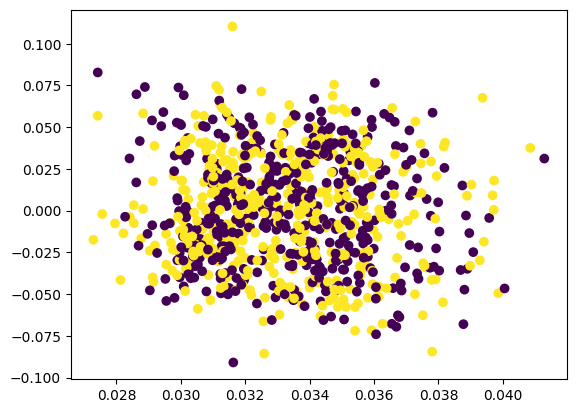

In [38]:
import matplotlib.pyplot as plt
plt.scatter(components[0], components[1], c=demo["MI"].to_list())